# Exercises for Section 4.3 Interpreting linear models

This notebook contains the exercises
from [Section 4.3 Interpreting linear models]()
in the **No Bullshit Guide to Statistics**.

### Notebook setup

In [1]:
# Ensure required Python modules are installed
%pip install --quiet numpy scipy seaborn pandas ministats


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# Figures setup
plt.clf()  # needed otherwise `sns.set_theme` doesn't work
sns.set_theme(
    context="paper",
    style="whitegrid",
    palette="colorblind",
    rc={"figure.figsize": (6, 1.6)},
)
%config InlineBackend.figure_format = "retina"

<Figure size 640x480 with 0 Axes>

In [4]:
# Simplified int and float __repr__
np.set_printoptions(legacy='1.25')

In [5]:
# Download datasets/ directory if necessary
from ministats import ensure_datasets
ensure_datasets()

datasets/ directory already exists.


$\def\stderr#1{\mathbf{se}_{#1}}$
$\def\stderrhat#1{\hat{\mathbf{se}}_{#1}}$
$\def\Mean{\textbf{mean}}$
$\def\Var{\textbf{var}}$
$\def\Std{\textbf{std}}$
$\def\Freq{\textbf{freq}}$
$\def\RelFreq{\textbf{relfreq}}$
$\def\CI#1{\textbf{CI}_{#1}}$
$\def\CIL#1{\textbf{L}_{#1}}$
$\def\CIU#1{\textbf{U}_{#1}}$
$\def\ci#1{\textbf{ci}_{#1}}$
$\def\cil#1{\textbf{l}_{#1}}$
$\def\ciu#1{\textbf{u}_{#1}}$
$\def\DMeans{\textbf{dmeans}}$
$\def\Prop{\textbf{prop}}$
$\def\DProps{\textbf{dprops}}$
$\def\Err{ {\Large \varepsilon}}$
$\def\calN{\mathcal{N}}$
$\def\Tdist{\mathcal{T}}$
$\def\Expon{\mathrm{Expon}}$

(this cell contains the macro definitions like $\stderr{\overline{\mathbf{x}}}$, $\stderrhat{}$, $\Mean$, ...)

## Exercises

### E4.13

<!-- {exercise:lm1-summary-questions} -->

Load the [students dataset](https://noBSstats.com/datasets/students.csv)
and fit a linear model `lm1` based on the formula `"score 1 + effort"`.
Answer the following questions based on the model fit summary table   `lm1.summary()`.

**a)** What is the $R$-squared of this model?

**b)** What are the best-fit parameter estimates $\widehat{\beta}_{0}$ and $\widehat{\beta}_{\texttt{effort}}$?

**c)** What is the log-likelihood of the fitted model?

**d)** What is the standard error of the slope estimate $\widehat{\beta}_{\texttt{effort}}$?

**e)** Report a 95% confidence interval for the slope parameter.

**f)** Report the $t$-statistic and the $p$-value
for the $t$-test of the slope parameter
that compares $H_0: \beta_{\texttt{effort}}=0$
and $H_A: \beta_{\texttt{effort}} \neq 0$.

**g)** What are the skewness and the kurtosis of the residuals?



In [6]:
# Load the students dataset
import pandas as pd
students = pd.read_csv("datasets/students.csv")

In [8]:
# Fit the linear model
import statsmodels.formula.api as smf
lm1 = smf.ols("score ~ 1 + effort", data=students).fit()

# Print the model fit summary table
lm1.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                  score   R-squared:                       0.773
Model:                            OLS   Adj. R-squared:                  0.756
Method:                 Least Squares   F-statistic:                     44.37
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.56e-05
Time:                        12:35:44   Log-Likelihood:                -44.140
No. Observations:                  15   AIC:                             92.28
Df Residuals:                      13   BIC:                             93.70
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     32.4658      6.155      5.275      0.000      19.169      45.763
effort         4.5049      0.676      6.661      0.000       3.044       5.966
==============================================================================
Omnibus:                        4.062   Durbin-Watson:                   2.667
Prob(Omnibus):                  0.131   Jarque-Bera (JB):                1.777
Skew:                           0.772   Prob(JB):                        0.411
Kurtosis:                       3.677   Cond. No.                         44.5
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

The answers for all questions can be read off the summary table.

In [9]:
# The table reports the Pearson Kurtosis value
from scipy.stats import kurtosis
kurtosis(lm1.resid, fisher=False)

3.676623802270679

In [10]:
# To obtain the Fisher "excess kurtosis" value, use:
kurtosis(lm1.resid)

0.676623802270679

### E4.14

<!-- {exercise:OECD-lifesat-vs-gdp-and-educ-tests} -->

Fit a linear model for life satisfaction (`lifesat`)
in the OECD BLI dataset
([`datasets/oecd_bli.csv`](https://noBSstats.com/datasets/oecd_bli.csv)).
Use the gross domestic product per capita (`gdp`)
and education (`educ`) variables as predictors.

**a)** Report the result of the $F$-test for the overall model,
which compares the null hypothesis $H_0: \beta_{\texttt{gdp}} = \beta_{\texttt{educ}} =0$
to the alternative hypothesis $H_A$
that at least one slope parameter is nonzero.

**b)** Report the $t$-statistic and the $p$-value
for the $t$-test of the `gdp` slope parameter $\beta_{\texttt{gdp}}$.
What can you conclude about the statistical significance of
the `gdp` predictor in the model?

**c)** Report the $t$-statistic and the $p$-value
for the $t$-test of the `educ` slope parameter.
What can you say about the predictor `educ`?


In [11]:
# Load the OECD Better Life Index dataset
oecd_bli = pd.read_csv("datasets/oecd_bli.csv")
oecd_bli.head(3)

,Country,educ,income,lifesat,salary,gdp
0,Mexico,42.0,16269.0,6.0,16230.0,23659.0
1,Greece,76.0,20791.0,5.8,27207.0,38397.0
2,Slovak Republic,92.0,21149.0,6.5,23619.0,40586.0


In [13]:
# Fit the linear model
import statsmodels.formula.api as smf
lm_lifesat = smf.ols("lifesat ~ 1 + gdp + educ", data=oecd_bli).fit()

# Print the model fit summary table
lm_lifesat.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                lifesat   R-squared:                       0.612
Model:                            OLS   Adj. R-squared:                  0.578
Method:                 Least Squares   F-statistic:                     18.11
Date:                Tue, 10 Nov 2026   Prob (F-statistic):           1.89e-05
Time:                        12:35:44   Log-Likelihood:                -10.750
No. Observations:                  26   AIC:                             27.50
Df Residuals:                      23   BIC:                             31.27
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      4.7643      0.515      9.252      0.000       3.699       5.830
gdp         3.026e-05    5.8e-06      5.216      0.000    1.83e-05    4.23e-05
educ           0.0031      0.007      0.451      0.656      -0.011       0.017
==============================================================================
Omnibus:                        2.499   Durbin-Watson:                   2.392
Prob(Omnibus):                  0.287   Jarque-Bera (JB):                1.152
Skew:                           0.411   Prob(JB):                        0.562
Kurtosis:                       3.622   Cond. No.                     4.02e+05
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 4.02e+05. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

The hypothesis test results are all displayed
in the above summary table,
but we'll now also show how to obtain them
by accessing specific attributes of the `lm_lifesat` object.

In [14]:
# a) F-test results
lm_lifesat.fvalue, lm_lifesat.f_pvalue

(18.11101129022381, 1.889352120449497e-05)

In part **b)**,
we want to test if the slope parameter $\beta_{\texttt{gdp}}$ differs from zero.

In [15]:
# b) t-test for the `gdp` slope parameter
lm_lifesat.tvalues["gdp"], lm_lifesat.pvalues["gdp"]

(5.215573975421682, 2.737045580001212e-05)

Conclusion: reject the null hypothesis $H_0: \beta_{\tt{gdp}} = 0$. The result of the $t$-test shows life satisfaction is correlated with GDP.
It seems that counties with higher GDP tend to have higher life satisfaction,
for the same level of education.

For part **c)**,
we want to test whether the slope parameter $\beta_{\texttt{educ}}$ differs from zero.
The results of the $t$-test are:

In [16]:
# c) t-test for the `educ` slope parameter
lm_lifesat.tvalues["educ"], lm_lifesat.pvalues["educ"]

(0.45074300788308647, 0.656395391842408)

Conclusion: fail to reject the null hypothesis $H_0: \beta_{\tt{educ}} = 0$.
This tells us we don't have evidence of an association between education and life satisfaction, after controlling for GDP.

### E4.15

<!-- {exercise:predict-new-doctor-alc0-weed3-exrc5} -->

Repeat the calculations from code block [\[load-doctors-and-fit-lm2\]](#load-doctors-and-fit-lm2){reference-type="ref" reference="load-doctors-and-fit-lm2"}
to obtain the linear model `lm2` based on the formula `"score 1 + alc + weed + exrc"`,
fitted to the [doctors dataset](https://noBSstats.com/datasets/doctors.csv).

**a)** Use the model `lm2` to predict the mean sleep score $\mu_{S}$
for doctors who don't drink ($\texttt{alc}=0$),
smoke three grams of marijuana per week ($\texttt{weed}=3$),
and exercise for five hours on average each week ($\texttt{exrc}=5$).

**b)** Construct a 90% confidence interval $\ci{\mu_{S},0.9}$
for the mean sleep score $\mu_{S}$
of doctors with the characteristics described in part **a)**.

**c)** Report a 90% prediction interval $\textbf{pi}_{S,0.9}$
for the actual sleep score $S$
of a doctor with the characteristics described in part **a)**.

Hint:
Use the method `lm2.get_prediction` to get the prediction result object
then call the method `.conf_int`
like we did in .

In [17]:
# Load the doctors dataset
doctors = pd.read_csv("datasets/doctors.csv")

# Fit the model `lm2`
formula = "score ~ 1 + alc + weed + exrc"
lm2 = smf.ols(formula, data=doctors).fit()

In [19]:
# a) 
newdoc_data = {"alc":0, "weed":3, "exrc":5}
pred_newdoc = lm2.get_prediction(newdoc_data)
pred_newdoc.predicted

array([66.22968939])

The prediction is $\hat{s} = 66.2$.

In [21]:
# b) Confidence interval for the mean score
pred_newdoc.conf_int(alpha=0.1)

array([[63.62453982, 68.83483897]])

We obtain a 90% confidence interval $\ci{\mu_{S},0.9} = [63.6, 68.8]$.

In [23]:
# c) Prediction interval for the sleep score
pred_newdoc.conf_int(obs=True, alpha=0.1)

array([[52.40688626, 80.05249253]])

The 90% prediction interval is $\textbf{pi}_{S,0.9} = [52.4, 80.1]$.

### E4.16

<!-- {exercise:influential-observations-students-dataset} -->

Consider the linear model `lm1`
for the [students dataset](https://noBSstats.com/datasets/students.csv)
that we obtained from the formula `"score 1 + effort"`.
In this exercise,
we'll identify an influential observation in the students dataset
and see how the parameter estimates change when we exclude that observation
from the students dataset.

**a)** Fit the linear model `lm1` and plot the best-fit line using `plot_reg`.
Display the parameter estimates $\widehat{\beta}_{0}$ and $\widehat{\beta}_{\texttt{effort}}$.

**b)** Use `plot_leverage_resid2` to produce a leverage plot for `lm1`.
Identify the index of the influential observation,
which has a high squared normalized residual and medium leverage.

**c)** Use the code `subset = students.drop(index=idx)`
to obtain the `subset` of the `students` dataset
without the influential observation at index `idx`
that you identified in part **b)**.

**d)** Fit a linear model `lm1_subset` for the `subset` dataset
based on the formula `"score 1 + effort"`.
Use `plot_reg` to plot the best-fit line for `lm1_subset`.
Display the parameter estimates $\widehat{\beta}_{0(\texttt{idx})}$ and $\widehat{\beta}_{\texttt{effort}(\texttt{idx})}$
of the model `lm1_subset` fitted to the data excluding observation `idx`.

What can you conclude about the influence of observation `idx`?

In [24]:
# Load the students dataset
students = pd.read_csv("datasets/students.csv")

# Number of observations
len(students)

15

Intercept    32.465809
effort        4.504850
dtype: float64

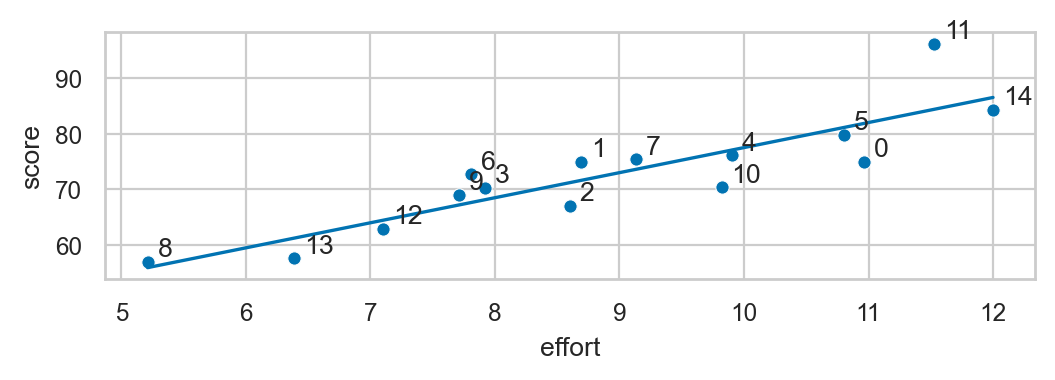

In [26]:
# a) Fit the linear model to the whole `students` dataset
import statsmodels.formula.api as smf
lm1 = smf.ols("score ~ 1 + effort", data=students).fit()

# Plot the linear model `lm1`
from ministats import plot_reg
ax = plot_reg(lm1)

# Add labels to individual data points
for idx, row in students.iterrows():
    ax.text(x=row["effort"]+0.08, y=row["score"]+1, s=idx)

# Print the parameter estimates
lm1.params

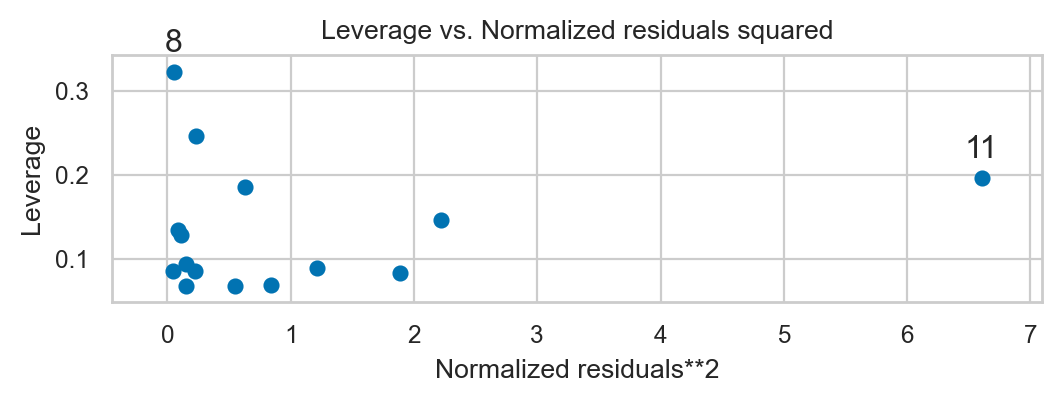

In [28]:
# b) Generate a leverage plot
from statsmodels.graphics.api import plot_leverage_resid2
plot_leverage_resid2(lm1);

In [30]:
# c) Select the subset that doesn't include influential observation
subset = students.drop(index=11)
len(subset)  # number of observations

14

Intercept    37.944172
effort        3.779757
dtype: float64

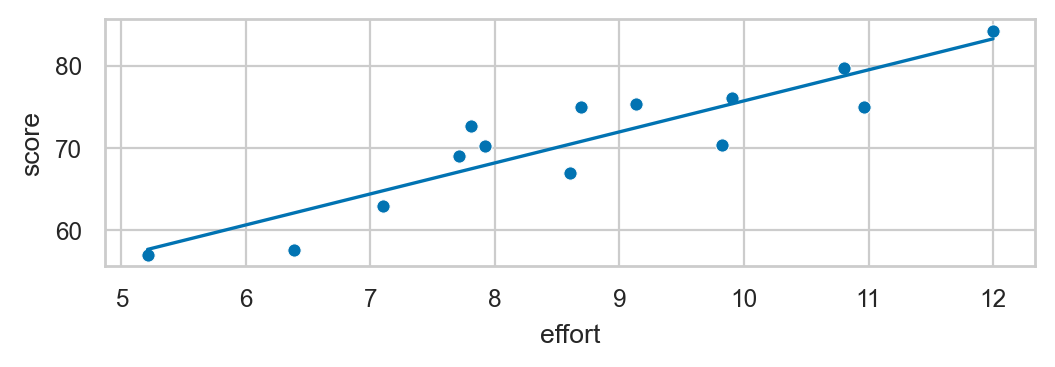

In [32]:
# d) Fit the linear model to the subset dataset
lm1_subset = smf.ols("score ~ 1 + effort", data=subset).fit()

# Plot the linear model `lm1_subset`
from ministats import plot_reg
ax = plot_reg(lm1_subset)

# Print the parameter estimates
lm1_subset.params


We see that the slope estiamte $\widehat{\beta}_{\texttt{effort}(11)} = 3.8$
we obtained after excluding the influential observation at index 11
is lower than the slope estiamte we obtained from the whole dataset $\widehat{\beta}_{\texttt{effort}} = 4.5$.
This shows that a single observation (the 96.2 score)
had a strong influence on the linear model `lm1`.
However,
there is no reason to exclude observation 11:
it just reflects one student who did really well.
The analysis in this exercise illustrates how to assess
a linear model's sensitivity to particular observations.